# Прогнозирование изменения активности пользователей приложения в течение ближайшего месяца.

Чем активнее наши пользователи – тем выше нагрузка на сервера. И в последнее время нам всё чаще приходят жалобы, что приложение подвисает. Требуется спрогнозировать, как изменится активность пользователей в течение ближайшего месяца.

In [220]:
import orbit #общий пакет
from orbit.models import DLT #один из вариантов модели
from orbit.diagnostics.plot import plot_predicted_data, plot_predicted_components #для рисования предсказаний

import pandas as pd
import pandahouse as ph
import numpy as np
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
import arviz as az #это полезно для визуализации MCMC
sns.set(rc={'figure.figsize':(16,6)}, style="whitegrid")

warnings.filterwarnings('ignore', message='findfont: Generic family \'sans-serif\' not found')

In [221]:
#коннект к базе данных

connection = {'host': 'http://clickhouse.lab.karpov.courses:8123',
                      'database':'simulator_20260920',
                      'user':'student', 
                      'password':'dpo_python_2020'
                     }

## Выбор основной метрики

Основной метрикой будем считать DAU (число уникальных пользователей в день). Т.к нагрузка на серверы будет увеличиваться с ростом количества активных пользователей и количества их сессий.

Временное разрешение возмем день. Часовое разрешение не подходит из-за слишком большого шума и  сезонности в течение суток.

Для прогноза активности пользователей в ближайшей месяц у нас не хватает данных. Чтобы провалидировать горизонт 30 дней нужен данные длиной хотя бы: train (66–90 дней) + тест (30 дней) — то есть суммарно 100–120 дней. У нас данных на 66. Поэтому сделаем прогноз на 7 дней.

Дополнительные регрессоры использованы не будут, т.к. для этого необходимо знать их будущие значения. Такие регрессоры отсутствуют. 

In [222]:
dau = '''
SELECT toDate(time) date, uniq(user_id) DAU
FROM simulator_20260920.feed_actions
WHERE date < today() # Уберем из данных незавершенный сегодняшний день. 
GROUP BY date
ORDER BY date
'''

In [223]:
df_dau = ph.read_clickhouse(query=dau, connection=connection)
df_dau.head()

,date,DAU
0,2026-08-01,878
1,2026-08-02,2238
2,2026-08-03,3105
3,2026-08-04,3721
4,2026-08-05,4617


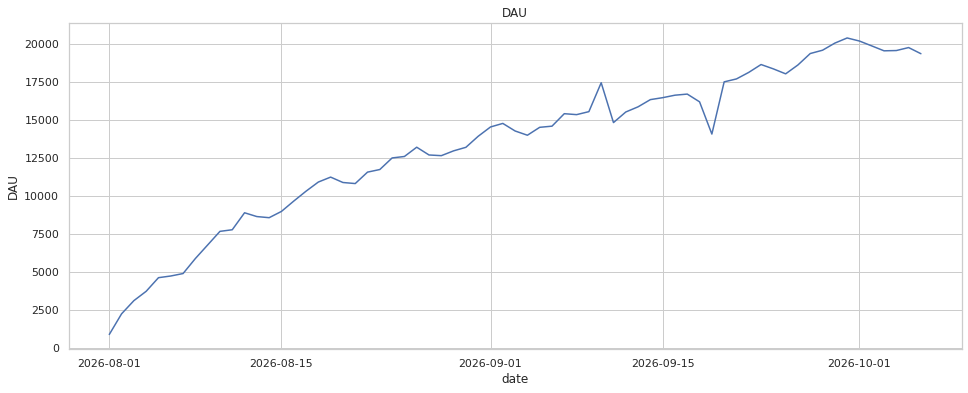

In [224]:
sns.lineplot(data=df_dau, x='date', y='DAU')
plt.title("DAU")
plt.show()

In [225]:
query = '''
SELECT toStartOfHour(time) hour_time, uniq(user_id) active_users
FROM simulator_20260920.feed_actions
WHERE hour_time < today()
GROUP BY hour_time
ORDER BY hour_time
'''

In [226]:
users_to_hour = ph.read_clickhouse(query=query, connection=connection)

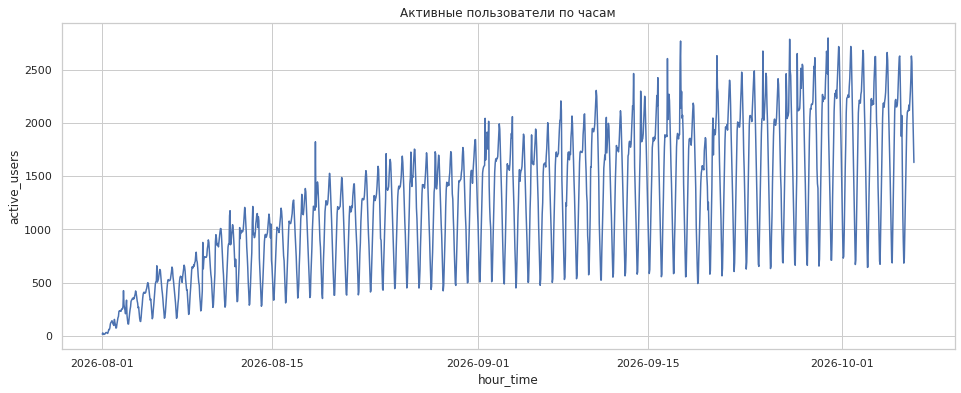

In [227]:
sns.lineplot(data=users_to_hour, x='hour_time', y='active_users')
plt.title("Активные пользователи по часам")
plt.show()

## Построение модели и её валидация

### Проверка сезонности данных

Для нашего приложения преположим, что сезонность равна неделе.
В этом случае, в будни активность пользователей будет выше чем в выходные дни.

Построим DAU по датам, а потом сгруппируем по дню недели и сравним средние:

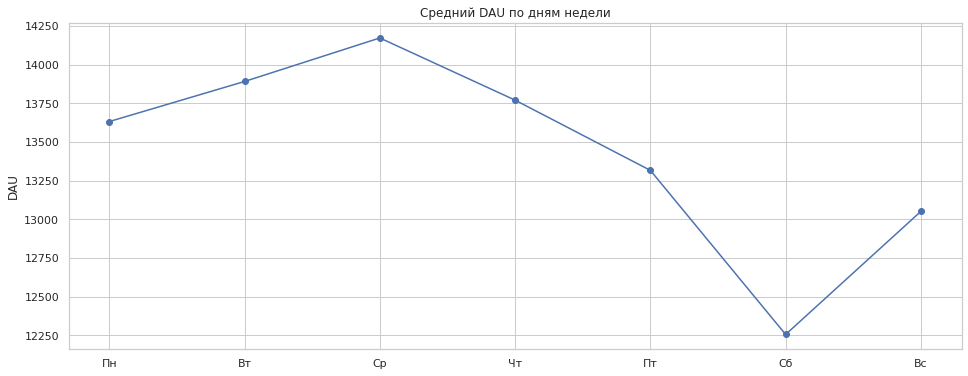

In [228]:
df_dau['day_of_week'] = df_dau['date'].dt.dayofweek

# Средние по дням недели
plt.errorbar(day_avg.index, day_avg.values, fmt='o-')
plt.xticks(range(7), ['Пн','Вт','Ср','Чт','Пт','Сб','Вс'])
plt.title('Средний DAU по дням недели')
plt.ylabel('DAU')
plt.grid(True)
plt.show()


На графике видно, что средние значения DAU по будням выше, чем в выходные. Значит сезонность есть и равна 7 дням (неделе).

### Алгоритм MAP

In [229]:
dlt = DLT(response_col="DAU", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000) #количество сэмплов бутстрапа для доверительного интервала

2026-10-07 20:36:46 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.


In [230]:
dlt.fit(df_dau)

In [231]:
future_df = dlt.make_future_df(periods=7)
future_df.head()

,date
0,2026-10-07
1,2026-10-08
2,2026-10-09
3,2026-10-10
4,2026-10-11


In [232]:
predicted_df = dlt.predict(df=future_df)
predicted_df.head()

,date,prediction_5,prediction,prediction_95
0,2026-10-07,19117.091775,20070.703750,21010.070010
1,2026-10-08,18711.425505,19660.797590,20661.478396
2,2026-10-09,17653.721774,18785.237862,19948.767913
3,2026-10-10,17120.775607,18457.456080,19787.751401
4,2026-10-11,17466.054866,19132.014154,20735.198626


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

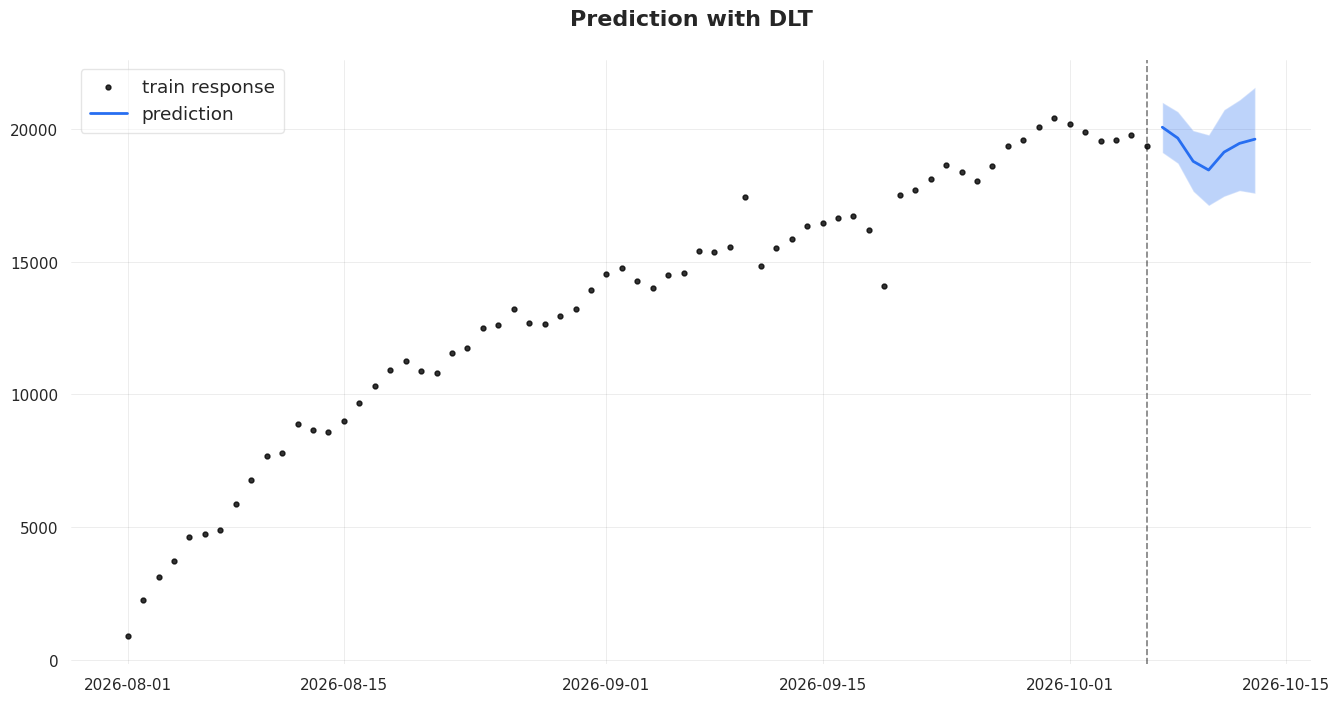

In [233]:
_ = plot_predicted_data(df_dau, predicted_df, "date", 'DAU', title='Prediction with DLT')

In [234]:
predicted_df = dlt.predict(df=future_df, 
                           decompose=True) #говорит, что нам нужна декомпозиция предсказания
predicted_df.head(5)

,date,prediction_5,prediction,prediction_95,trend_5,trend,trend_95,seasonality_5,seasonality,seasonality_95,regression_5,regression,regression_95
0,2026-10-07,19031.393895,20070.703750,20979.570711,18367.054895,19406.364750,20315.231711,664.3390,664.3390,664.3390,0.0,0.0,0.0
1,2026-10-08,18599.494074,19660.797590,20780.501709,18189.939074,19251.242590,20370.946709,409.5550,409.5550,409.5550,0.0,0.0,0.0
2,2026-10-09,17638.359787,18785.237862,20071.795091,18023.964787,19170.842862,20457.400091,-385.6050,-385.6050,-385.6050,0.0,0.0,0.0
3,2026-10-10,16988.190641,18457.456080,19881.100140,17680.955641,19150.221080,20573.865140,-692.7650,-692.7650,-692.7650,0.0,0.0,0.0
4,2026-10-11,17564.393614,19132.014154,20733.290130,17609.801114,19177.421654,20778.697630,-45.4075,-45.4075,-45.4075,0.0,0.0,0.0


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

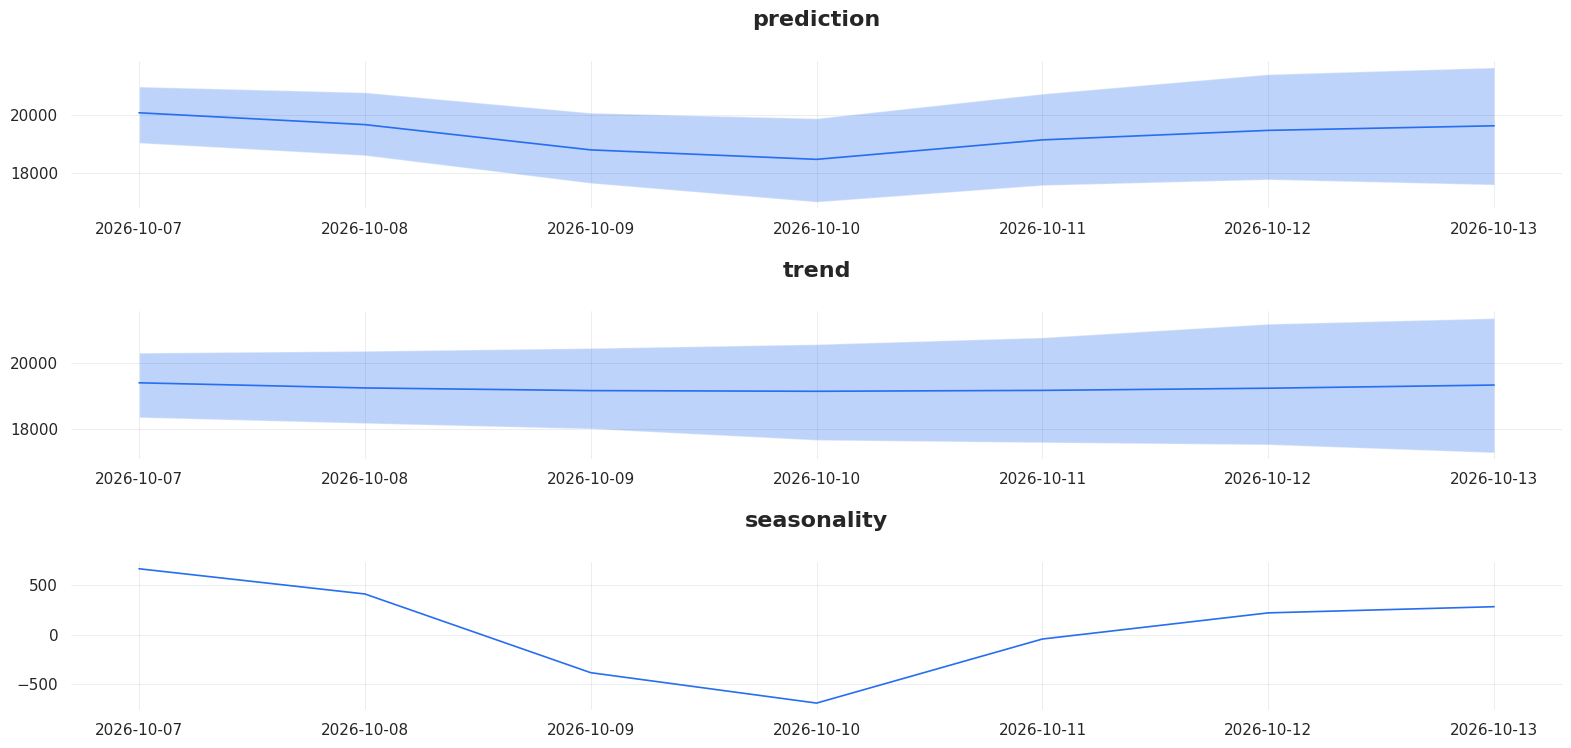

In [235]:
_ = plot_predicted_components(predicted_df, "date", plot_components=['prediction', 'trend', 'seasonality'])

### Алгоритм MCMC

In [236]:
dlt_mcmc = DLT(seasonality=7, response_col="DAU", date_col="date", 
               estimator='stan-mcmc', #новый алгоритм оценки
               num_warmup=2000, #время "разогрева"
               num_sample=1000) #время сэмплирования

In [237]:
dlt_mcmc.fit(df_dau)

2026-10-07 20:36:49 - orbit - INFO - Sampling (PyStan) with chains: 4, cores: 6, temperature: 1.000, warmups (per chain): 500 and samples(per chain): 250.


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

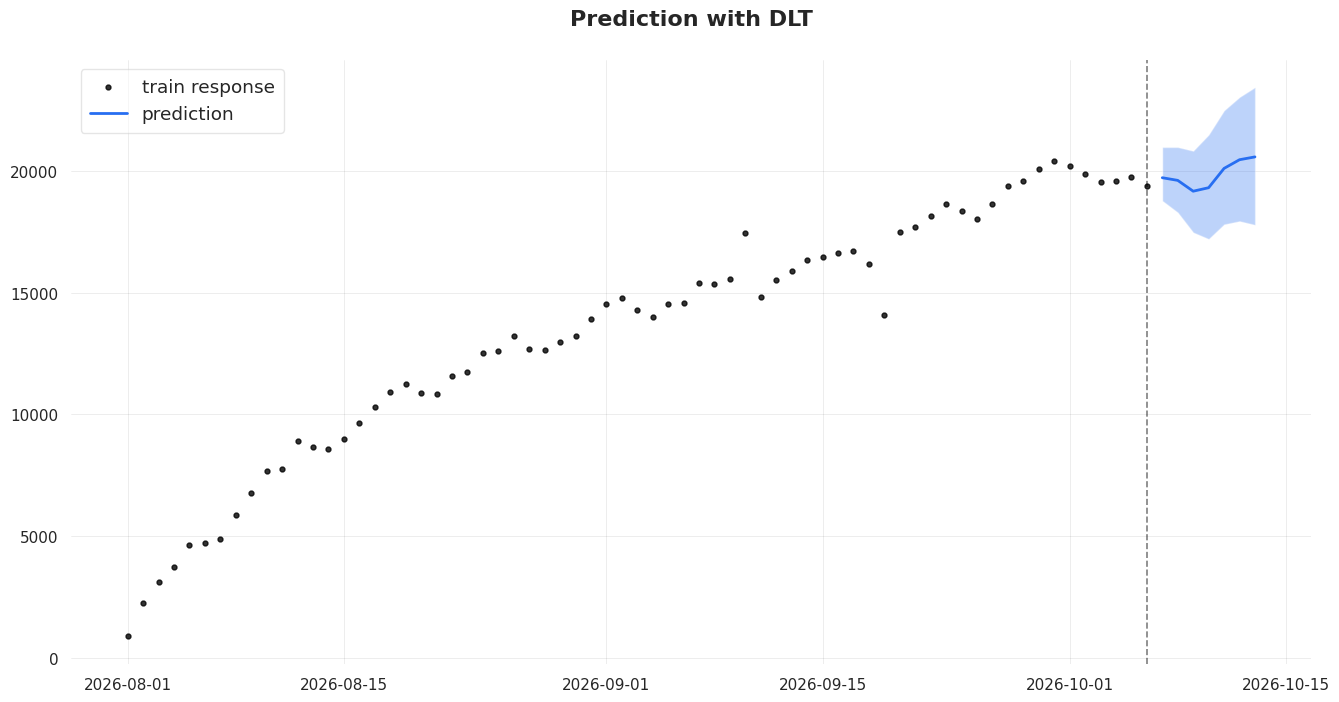

In [238]:
future_df = dlt_mcmc.make_future_df(periods=7)

predicted_df = dlt_mcmc.predict(df=future_df)

_ = plot_predicted_data(df_dau, predicted_df, "date", 'DAU', title='Prediction with DLT')

In [239]:
predicted_df = dlt_mcmc.predict(df=future_df, decompose=True)
predicted_df

,date,prediction_5,prediction,prediction_95,trend_5,trend,trend_95,seasonality_5,seasonality,seasonality_95,regression_5,regression,regression_95
0,2026-10-07,18660.329125,19715.775876,20857.467328,18344.825933,19390.540882,20470.102084,13.546575,249.37050,883.686550,0.0,0.0,0.0
1,2026-10-08,18352.128820,19595.932132,20895.292180,18176.138910,19523.948573,20871.501348,-177.656300,-25.21655,617.272750,0.0,0.0,0.0
2,2026-10-09,17577.730041,19183.203352,20945.558016,18062.287261,19664.608837,21292.126530,-760.381200,-484.02900,-63.658405,0.0,0.0,0.0
3,2026-10-10,17322.278139,19285.324156,21381.496121,17895.564835,19774.410561,21648.155502,-985.402650,-472.03400,-28.671710,0.0,0.0,0.0
4,2026-10-11,17911.996947,20015.575447,22507.869057,17843.962440,19925.759772,22326.199082,-293.204150,152.44500,378.778150,0.0,0.0,0.0
5,2026-10-12,17919.282056,20316.069420,22882.135004,17602.468401,20070.509220,22725.123311,-0.391645,256.56700,490.675600,0.0,0.0,0.0
6,2026-10-13,17861.748222,20567.786614,23391.079661,17587.222376,20353.760550,23292.757651,-24.595380,154.46300,508.910050,0.0,0.0,0.0


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

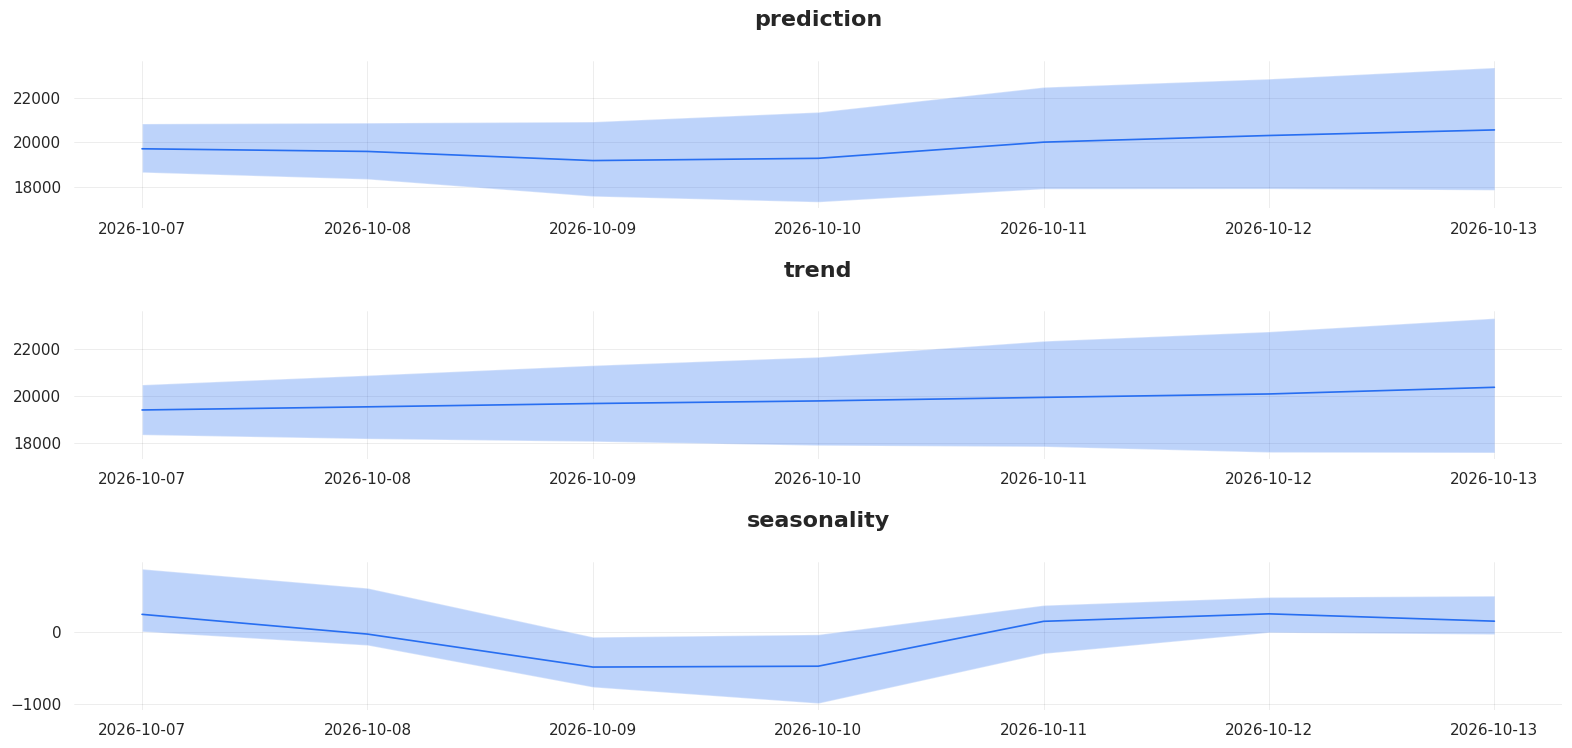

In [240]:
_ = plot_predicted_components(predicted_df, "date", plot_components=['prediction', 'trend', 'seasonality'])

## Проверка качества моделей

In [241]:
from orbit.diagnostics.backtest import BackTester 
from orbit.utils.params_tuning import grid_search_orbit

Так как данных небольшое количество и они не очень волотильны применим расширяющийся тип окна.

Модель MAP

In [242]:
#expanding

bt_exp = BackTester(
    model=dlt, #наша моделька
    df=df_dau, #датафрейм для обучения
    min_train_len=35, #самый маленький кусочек данных, с которого начинается обучение
    incremental_len=7, #на сколько происходит прирост тренировочных данных
    forecast_len=7, #горизонт пронозирования
    window_type="expanding" #тип окошка
)

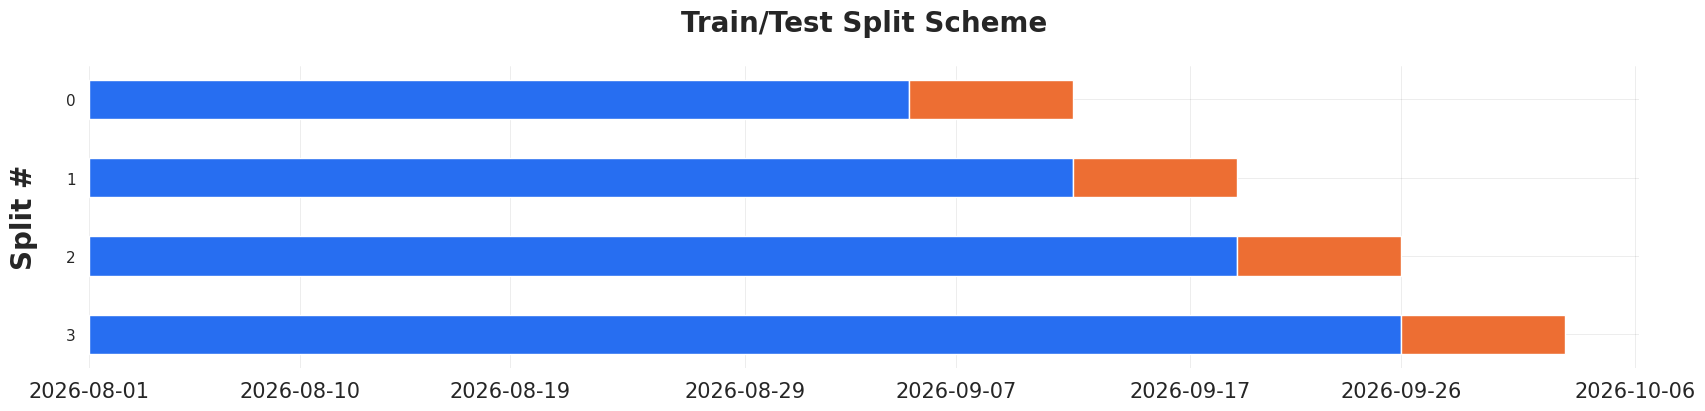

In [243]:
bt_exp.plot_scheme()

In [244]:
bt_exp.fit_predict() #обучаем
bt_exp.score() #выводим метрики

,metric_name,metric_values,is_training_metric
0,smape,0.049701,False
1,wmape,0.048860,False
2,mape,0.050989,False
3,mse,954714.241157,False
4,mae,841.167796,False
5,rmsse,0.915037,False


Модель MCMC

In [245]:
bt_exp_mcmc = BackTester(
    model=dlt_mcmc, #наша моделька
    df=df_dau, #датафрейм для обучения
    min_train_len=35, #самый маленький кусочек данных, с которого начинается обучение
    incremental_len=7, #на сколько происходит прирост тренировочных данных
    forecast_len=7, #горизонт пронозирования
    window_type="expanding" #тип окошка
)

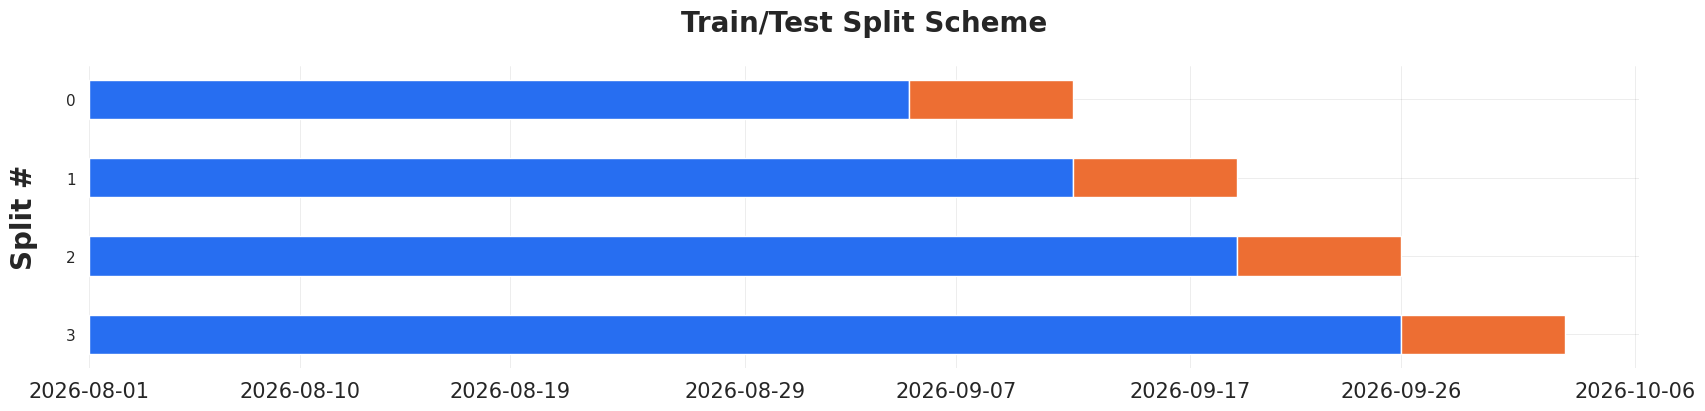

In [246]:
bt_exp_mcmc.plot_scheme()

In [247]:
bt_exp_mcmc.fit_predict() #обучаем

2026-10-07 20:36:59 - orbit - INFO - Sampling (PyStan) with chains: 4, cores: 6, temperature: 1.000, warmups (per chain): 500 and samples(per chain): 250.


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

2026-10-07 20:37:02 - orbit - INFO - Sampling (PyStan) with chains: 4, cores: 6, temperature: 1.000, warmups (per chain): 500 and samples(per chain): 250.


... (10 outputs left out)

chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

In [248]:
bt_exp_mcmc.score() #выводим метрики

,metric_name,metric_values,is_training_metric
0,smape,0.046368,False
1,wmape,0.045580,False
2,mape,0.047925,False
3,mse,971010.745572,False
4,mae,784.693868,False
5,rmsse,0.922814,False


In [249]:
bt_exp.score() #выводим метрики

,metric_name,metric_values,is_training_metric
0,smape,0.049701,False
1,wmape,0.048860,False
2,mape,0.050989,False
3,mse,954714.241157,False
4,mae,841.167796,False
5,rmsse,0.915037,False


Сравнивая метрики ошибок моделей, видно что минимальные метрики у модели MCMC, кроме метрики rmsse и mse. Можно сделать вывод, что модель с MCMC алгоритом более удачная.

### Подбор оптимального параметра угасания тренда для модели MCMC.

Модель MCMC

In [250]:
best_params_mcmc, tuned_df_mcmc = grid_search_orbit(param_grid={"damped_factor": np.arange(0.1, 1.0, 0.1)}, #наш параметр
                                        model=dlt_mcmc,
                                        df=df_dau,
                                        min_train_len=35,
                                        incremental_len=7,
                                        forecast_len=7,
                                        metrics=None, #смотрим smape по умолчанию
                                        criteria="min", #говорим, что нам нужна минимизация
                                        verbose=True) #пусть печатает процесс выполнения

  0%|          | 0/9 [00:00<?, ?it/s]

2026-10-07 20:37:15 - orbit - INFO - tuning hyper-params {'damped_factor': 0.1}
2026-10-07 20:37:15 - orbit - INFO - Sampling (PyStan) with chains: 4, cores: 6, temperature: 1.000, warmups (per chain): 500 and samples(per chain): 250.


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

... (172 outputs left out)

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

2026-10-07 20:39:28 - orbit - INFO - tuning metric:0.047592


In [251]:
best_params_mcmc

[{'damped_factor': 0.1}]

In [252]:
tuned_df_mcmc

,damped_factor,metrics
0,0.1,0.044334
1,0.2,0.044814
2,0.3,0.045180
3,0.4,0.046352
4,0.5,0.046481
5,0.6,0.045752
6,0.7,0.044628
7,0.8,0.045575
8,0.9,0.047592


У модели параметр угасания тренда с минимальной ошибкой равен 0.1. Но т.к. разница между метрикой ошибки стандартного параметра 0.8 (0.045575) и парамером равным 0.1 (0.044334) незначительная, то менять параметр в модели нет необходимости.

### Сходимость цепей МСМС

array([[<Axes: title={'center': 'obs_sigma'}>,
        <Axes: title={'center': 'obs_sigma'}>]], dtype=object)

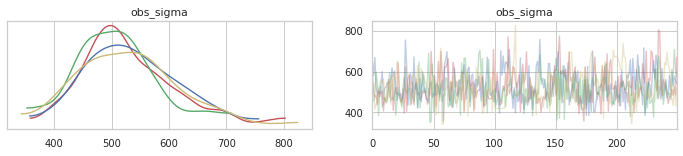

In [253]:
az.plot_trace(params, chain_prop={"color": ['r', 'b', 'g', 'y']}, var_names = "obs_sigma")

Слева все четыре цепи дают почти совпадающие распределения: пики в одном месте (500), разбросы перекрываются. Справа все четыре цепи колеблются вокруг одного уровня (500) на всём протяжении Это признак того, что алгоритм работает хорошо.

## Выбор наиболее удачной модели. Интерпретация результов.

В ходе решения задачи по прогнозированию изменения активности пользователей в течение ближайшего месяца были построены и провалидированы две модели с приглушением локального тренда (DLT) по алгоритму MAP и MCMC. Основной метрикой было принято DAU с дневным временным разрешением. Горизонт прогнозирования был снижен до 7 дней, из-за недостаточного количества данных.

Была проведена проверка качества моделей с помощью бэктестирования. По результатм которой, сравнивая метрики ошибок было определено, что модель с MCMC алгоритом более удачная. Для этой модели была проведена диагностика - сходимость цепей, подтверждающая, что модель MCMC сходится.

Недельный прогноз по этой модели держится в диапазоне 19200–20000, с провалом до ~19170–19300 в середине периода (9–10 октября) и набору  к 13-му числу 20549 пользователей. Форма кривой повторяет недельную сезонность. Тренд почти плоский с медленным подъёмом.


Активность за неделю практически не изменится: она останется на плато около 19 200–20 600 DAU с характерным недельным ритмом — спад к выходным и восстановление к следующей неделе.
